# The efficiency-uniformity front: what the whole trade-off looks like, and who sits on it

**Question:** What is the whole trade-off between diffraction efficiency and uniformity on the 10 x 10 trap task, and does any single method of the product sit on it?

- Level: 4, beyond the state of the art (claim BS-5).
- Prerequisites: `05-optimization/01-the-cost-and-its-gradient`, and `03-gerchberg-saxton/02-weights-for-uniformity` for the loops that give the single points.
- Reading time: about 30 minutes. The notebook runs in about a minute and a half.

## Objectives

Every method in the literature reports its quality as one pair of numbers, an efficiency and a uniformity, and the choice between methods is usually a choice between pairs. But a pair is one point of a curve: change the weight of a cost, the number of iterations or the efficiency target and the same method lands somewhere else. This notebook asks what the curve is. By the end you can:

- place any hologram of a trap array in the plane of efficiency and uniformity, and say what dominating another one means;
- state the loss that B5 minimises, and say what its two terms and its parameter $\lambda$ do;
- run the single-point methods of the product and the continuation that traces the front, and read both on one figure;
- decide from the numbers whether a method sits on the front, and by how much it falls short;
- stress the claim with a stronger baseline than the benchmark's, and say what survives.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m05_gaa, m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b5_pareto
from pipeline.model.holo.methods.beyond.b5_pareto import hypervolume
from pipeline.model.holo.methods.optim import m09_direct_search, m11_wirtinger_adam

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C12 of `data/examples/cases.json`, the calibration task used throughout the optimisation topic.

- Owner: this repository; the case is synthetic and follows the 10 x 10 task of Di Leonardo, Ianni and Ruocco (2007).
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C12.

In [2]:
# case C12: the optical setup and the 100 traps of the 10 x 10 task
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
print(rec["case_id"], "|", len(target.traps), "traps | SLM", setup.n_pix, "x", setup.n_pix, "pixels")

C12_calibration | 100 traps | SLM 256 x 256 pixels


## Method

### The plane and the loss

With $I_m$ the fraction of the input power that reaches trap $m$, the efficiency is $e = \sum_m I_m$ and the uniformity is $u = 1 - (\max I - \min I) / (\max I + \min I)$ of the intensities divided by their target weights (Di Leonardo et al., 2007). A larger $e$ and a larger $u$ are both better, so hologram A dominates hologram B when it is at least as good in both and strictly better in one. The set of holograms that nothing dominates is the Pareto front. A method with a free parameter, such as the weight $f$ of the cost of Polin et al. (2005) or the number of iterations, traces a curve in this plane; a method without one gives a point.

B5 traces the curve by a continuation on one loss. Writing $T_m = e_0 w_m / \sum_k w_k$ for the equal-trap target at the efficiency $e_0$ of a starting hologram,

$$L_\lambda(\phi) = (1 - \lambda)\,\frac{\sum_m (I_m - T_m)^2}{\sum_m T_m^2} \;-\; \lambda\,\frac{\sum_m I_m}{e_0}, \qquad \lambda \in [0, 1].$$

At $\lambda = 0$ the loss asks for equal traps at the efficiency $e_0$ and nothing more. At $\lambda = 1$ it asks for light only, and equality is not asked for at all. In between it trades one against the other. B5 solves the loss for a grid of $\lambda$ from 0 to 1, each time warm-started from the previous solution, with conjugate gradient, and keeps the non-dominated results. Dividing the two terms by $\sum T^2$ and by $e_0$ makes both dimensionless and of order one; that scaling is the pipeline's reading of the research dossier, which does not state one. The hypervolume is the area of the plane, measured from the origin, that the points dominate: a front that dominates more has a larger hypervolume.

The first cell runs only the two ends, $\lambda = 0$ and $\lambda = 1$, with 15 conjugate-gradient iterations each, to show what each term asks for before the whole curve is traced.

In [3]:
# the two ends of the loss: lambda = 0 asks for equal traps, lambda = 1 asks for light only
ends = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(1), n_lambda=2)
for lam, (eff, uni, sig) in zip(ends.meta["lambdas"], ends.meta["front"]):
    print(f"lambda {lam:.0f}: efficiency {eff:.4f}  uniformity {uni:.4f}  "
          f"rel. std {sig:.2f} %")
print(f"efficiency of the start (phase-fixed WGS): {ends.meta['e0']:.4f}")

lambda 0: efficiency 0.7921  uniformity 0.9999  rel. std 0.00 %
lambda 1: efficiency 0.8275  uniformity 0.0003  rel. std 82.25 %
efficiency of the start (phase-fixed WGS): 0.7921


The two ends behave as the loss says. At $\lambda = 0$ the array is perfectly equal, with a relative standard deviation of 0.00 percent and a uniformity of 0.9999, at an efficiency of 0.7921, which is exactly the $e_0$ of the start. At $\lambda = 1$ the optimiser has lifted the efficiency to 0.8275 and given up on equality: the relative standard deviation is 82.25 percent and the uniformity is 0.0003, so one trap carries almost all the light and another almost none. The two ends are far apart in uniformity, from 0.9999 to 0.0003, and close in efficiency, 0.7921 to 0.8275, a gain of 4.5 percent of the light. This is the first fact about the front, and the cells below measure it with the whole curve: the trade-off on this task is steep, and almost all of it is paid in uniformity.

## State of the art

The single-point methods are the state of the art that B5 is measured against. Each runs here as the pipeline's own implementation, with the benchmark's budget of 30 iterations and the same seed: plain Gerchberg-Saxton (M04), the generalized adaptive additive loop (M05) and the weighted loop (M06) of Di Leonardo et al. (2007), and phase-fixed weighted GS (M07), the large-array method of Kim et al. (2019). The first cell runs those four.

In [4]:
# four projection methods at the benchmark budget of 30 iterations, seed 1
h04 = m04_gs.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h05 = m05_gaa.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h06 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h07 = m07_phase_fixed_wgs.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
for name, h in (("M04 GS", h04), ("M05 GAA", h05), ("M06 GSW", h06), ("M07 PF-WGS", h07)):
    print(f"{name:11s} efficiency {h['efficiency']:.4f}  uniformity {h['uniformity']:.4f}")

M04 GS      efficiency 0.8105  uniformity 0.6172
M05 GAA     efficiency 0.8089  uniformity 0.7053
M06 GSW     efficiency 0.7971  uniformity 0.9793
M07 PF-WGS  efficiency 0.7914  uniformity 0.9428


Two more points come from the optimisation family. Direct search (M09) changes one pixel at a time to lower the cost of Polin et al. (2005), $C = -\langle I \rangle + f \sigma$, with $f = 0.5$; it pays an efficiency price for uniformity by construction. Wirtinger-Adam (M11), from the previous notebook, minimises the quadratic loss by gradient steps.

In [5]:
# direct search (2 sweeps over the pixels) and Wirtinger-Adam (30 iterations), same task and seed
h09 = m09_direct_search.run(setup, target, budget=Budget(2), rng=Rng(1)).history[-1]
h11 = m11_wirtinger_adam.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
for name, h in (("M09 DS", h09), ("M11 Adam", h11)):
    print(f"{name:11s} efficiency {h['efficiency']:.4f}  uniformity {h['uniformity']:.4f}")

M09 DS      efficiency 0.6584  uniformity 0.9994
M11 Adam    efficiency 0.7629  uniformity 0.9327


The figure places the six results in the plane of efficiency and uniformity.

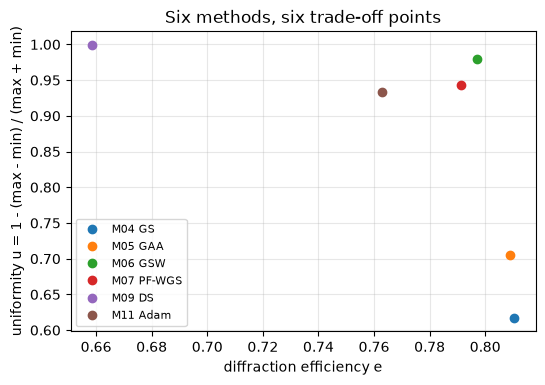

In [6]:
# the six single-point results in the plane of efficiency and uniformity
base = {"M04 GS": h04, "M05 GAA": h05, "M06 GSW": h06, "M07 PF-WGS": h07, "M09 DS": h09, "M11 Adam": h11}
fig, ax = plt.subplots(figsize=(6.0, 3.9))
for name, h in base.items():
    ax.plot(h["efficiency"], h["uniformity"], "o", label=name)
ax.set_xlabel("diffraction efficiency e")
ax.set_ylabel("uniformity u = 1 - (max - min) / (max + min)")
ax.set_title("Six methods, six trade-off points")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

The six points fall into three groups. M04 and M05 have the highest efficiency, 0.8105 and 0.8089, and the lowest uniformity, 0.6172 and 0.7053: they are the classical loops that put light in the traps and leave the traps unequal. M06 has an efficiency of 0.7971 and a uniformity of 0.9793, and M07 sits at 0.7914 and 0.9428 after the same 30 iterations; M11 is near them at 0.7629 and 0.9327. M09 is alone at the uniform end, with a uniformity of 0.9994 and an efficiency of only 0.6584, which is the price of its weight $f = 0.5$. The figure shows six points, and nothing in it says whether a point could be moved up or to the right with the same method. It cannot show the curve that each parameter would trace, and that is the gap B5 addresses: the literature compares these points, and no source reports the whole front on one task.

## Beyond the state of the art

### The front by continuation (BS-5)

The claim of B5 is that a continuation on one loss returns the whole front at the price of a few conjugate-gradient runs, and that no single-point method sits on it. The next cell runs it with 20 values of $\lambda$ and 15 conjugate-gradient iterations for each, and prints seven of the 20 points.

In [7]:
# the front: 20 values of lambda, 15 conjugate-gradient iterations each, each warm-started from its neighbour
res_b5 = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(1))
front = res_b5.meta["front"]
for k in (0, 3, 6, 9, 12, 15, 19):
    print(f"lambda {res_b5.meta['lambdas'][k]:.2f}: efficiency {front[k, 0]:.4f}  "
          f"uniformity {front[k, 1]:.4f}  rel. std {front[k, 2]:.2f} %")
print(f"points kept as non-dominated: {len(res_b5.meta['pareto'])} of {len(front)}")

lambda 0.00: efficiency 0.7921  uniformity 0.9999  rel. std 0.00 %
lambda 0.16: efficiency 0.7993  uniformity 0.9794  rel. std 0.83 %
lambda 0.32: efficiency 0.8056  uniformity 0.9539  rel. std 1.97 %
lambda 0.47: efficiency 0.8085  uniformity 0.9009  rel. std 3.62 %
lambda 0.63: efficiency 0.8119  uniformity 0.8228  rel. std 6.95 %
lambda 0.79: efficiency 0.8168  uniformity 0.7065  rel. std 12.83 %
lambda 1.00: efficiency 0.8296  uniformity 0.0085  rel. std 74.74 %
points kept as non-dominated: 20 of 20


The front is a curve, not a cloud: all 20 points are kept as non-dominated. Its efficiency runs from 0.7921 to 0.8296 while its uniformity runs from 0.9999 to 0.0085, and most of the loss of uniformity comes at the end of the curve, between $\lambda = 0.79$ and $\lambda = 1$. Now the claim: for each single point, the cell counts the front points that dominate it, and reads the efficiency the front offers at the same uniformity. The cell also compares the hypervolume of the front with that of the single points, which is the acceptance criterion of B5 in the method ladder.

In [8]:
# for every single point: the front points that dominate it, and the front efficiency at its uniformity
by_uniformity = np.argsort(front[:, 1])
for name, h in base.items():
    e, u = h["efficiency"], h["uniformity"]
    better = (front[:, 0] >= e) & (front[:, 1] >= u) & ((front[:, 0] > e) | (front[:, 1] > u))
    offered = np.interp(u, front[by_uniformity, 1], front[by_uniformity, 0])
    print(f"{name:11s} dominated by {int(better.sum()):2d} front points | "
          f"front efficiency at its uniformity {offered:.4f} "
          f"against {e:.4f}")
pairs = {k: [h["efficiency"], h["uniformity"]] for k, h in base.items()}
hv_six = hypervolume(np.array(list(pairs.values())))
hv_four = hypervolume(np.array([pairs[k] for k in ("M04 GS", "M05 GAA", "M09 DS", "M06 GSW")]))
print(f"hypervolume of the front: {res_b5.meta['hypervolume']:.4f}")
print(f"hypervolume of the six points: {hv_six:.4f} | of the four of the criterion: {hv_four:.4f}")

M04 GS      dominated by  5 front points | front efficiency at its uniformity 0.8189 against 0.8105
M05 GAA     dominated by  6 front points | front efficiency at its uniformity 0.8169 against 0.8089
M06 GSW     dominated by  1 front points | front efficiency at its uniformity 0.7993 against 0.7971
M07 PF-WGS  dominated by  8 front points | front efficiency at its uniformity 0.8064 against 0.7914
M09 DS      dominated by  1 front points | front efficiency at its uniformity 0.7922 against 0.6584
M11 Adam    dominated by  8 front points | front efficiency at its uniformity 0.8071 against 0.7629
hypervolume of the front: 0.8180
hypervolume of the six points: 0.8032 | of the four of the criterion: 0.8032


The figure draws the front and the six single points together.

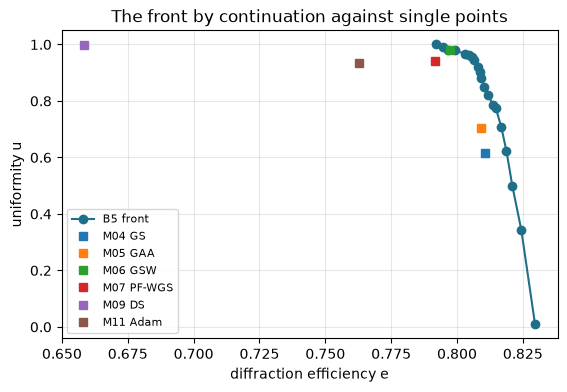

In [9]:
# the front and the six single points in one plane
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(front[:, 0], front[:, 1], "o-", color="#1f6f8b", label="B5 front")
for name, h in base.items():
    ax.plot(h["efficiency"], h["uniformity"], "s", label=name)
ax.set_xlabel("diffraction efficiency e")
ax.set_ylabel("uniformity u")
ax.set_title("The front by continuation against single points")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

Every one of the six single points is dominated: between 1 and 8 points of the front are at least as good in both measures and better in one. The margins differ a great deal. At the uniformity of M09 the front offers an efficiency of 0.7922 against 0.6584, a gain of 0.1338 of the light. At the uniformity of M07 it offers 0.8064 against 0.7914, and for M11, 0.8071 against 0.7629. For the classical loops the margin is about 0.008, and for M06 it is the smallest, 0.7993 against 0.7971. The hypervolume of the front is 0.8180 against 0.8032 for the six points and for the four of the criterion, so the acceptance criterion of B5 holds. What the figure does not say is how robust the margin of M06 is: 0.0022 of the light is the difference between a point and the curve, and it comes from one seed and one budget. The hypervolume is also a blunt tool here, because the origin is far and every point already covers about 0.8 of the unit square.

### A stronger baseline than the benchmark's

The benchmark fixes 30 iterations for every method, and the front above was started from a 30-iteration hologram. A fair test of a claim about a front should give the baseline more effort, since a single-point method is only one run. The strongest baseline for the uniform end is the weighted loop M06, whose uniformity keeps improving with iterations. The cell runs it for 100 iterations and counts the points of the front that it dominates.

In [10]:
# the strongest single-point baseline: weighted GS with 100 iterations instead of 30
res_long = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
e_long, u_long = res_long.history[-1]["efficiency"], res_long.history[-1]["uniformity"]
beaten = (e_long >= front[:, 0]) & (u_long >= front[:, 1]) & ((e_long > front[:, 0]) | (u_long > front[:, 1]))
print(f"M06, 100 iterations: efficiency {e_long:.4f}  uniformity {u_long:.4f}")
print(f"front points dominated by it: {int(beaten.sum())} of {len(front)}")

M06, 100 iterations: efficiency 0.8070  uniformity 0.9946
front points dominated by it: 7 of 20


The claim fails in part. A weighted-GS hologram of 100 iterations, at an efficiency of 0.8070 and a uniformity of 0.9946, dominates 7 of the 20 points of the front: the front underestimates what is reachable at the uniform end, because its continuation began from a start with an efficiency of only 0.7921 and spent 15 iterations per value. The front is not a property of the task alone but of the task, the starting hologram and the budget. B5 accepts a starting phase, so the repair is to begin the continuation from the better hologram. The cell does that with 8 values of $\lambda$ and 30 iterations each, and prints the two ends of the new front.

In [11]:
# the same continuation started from that better hologram: 8 values of lambda, 30 iterations each
res_warm = b5_pareto.run(setup, target, budget=Budget(30), rng=Rng(1), n_lambda=8, init=res_long.phi)
front_warm = res_warm.meta["front"]
print(f"uniform end of the new front: e {front_warm[0, 0]:.4f}  u {front_warm[0, 1]:.4f}")
print(f"efficiency end: e {front_warm[-1, 0]:.4f}  u {front_warm[-1, 1]:.4f}")
print(f"hypervolume, new front: {res_warm.meta['hypervolume']:.4f} | "
      f"first front: {res_b5.meta['hypervolume']:.4f}")

uniform end of the new front: e 0.8070  u 1.0000
efficiency end: e 0.8318  u 0.0126
hypervolume, new front: 0.8174 | first front: 0.8180


The figure draws both fronts and the 100-iteration point.

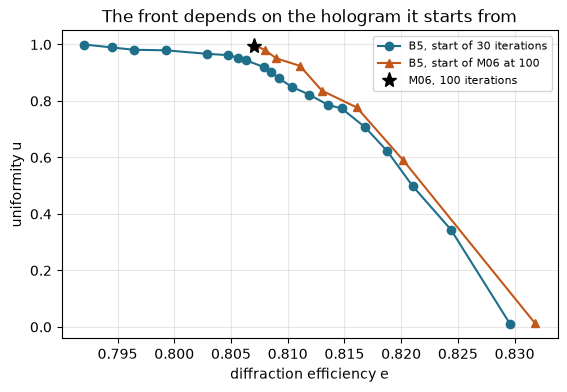

In [12]:
# both fronts and the long weighted-GS point
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(front[:, 0], front[:, 1], "o-", color="#1f6f8b", label="B5, start of 30 iterations")
ax.plot(front_warm[:, 0], front_warm[:, 1], "^-", color="#c2571a", label="B5, start of M06 at 100")
ax.plot(e_long, u_long, "k*", markersize=11, label="M06, 100 iterations")
ax.set_xlabel("diffraction efficiency e")
ax.set_ylabel("uniformity u")
ax.set_title("The front depends on the hologram it starts from")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

The new front starts where the stronger baseline ends: its uniform end is at an efficiency of 0.8070 and a uniformity of 1.0000, which matches the efficiency of M06 at 100 iterations to four digits and removes the remaining 0.0054 of non-uniformity, and its efficiency end reaches 0.8318 against 0.8296 for the first front. In the figure the orange curve lies above the blue one on the uniform side and below or equal to it nowhere that matters. The hypervolume, 0.8174 for 8 values of $\lambda$ against 0.8180 for 20, barely moves, which confirms that it cannot resolve this difference. The figure does not show that the new front is the true Pareto front of the task: it only shows that the old one was not. A third start, or more iterations per value, would likely move it again, and this notebook has no estimate of the limit. The safe statement is a dependence: the front that B5 returns is as good as the hologram it is started from, and no better.

## Results

**Answer:** On the 10 x 10 task the whole trade-off is a curve of 20 non-dominated points that runs from an efficiency of 0.7921 and a uniformity of 0.9999 to an efficiency of 0.8296 and a uniformity of 0.0085: it gains 4.7 percent of the light and loses all the uniformity, so the trade-off is steep and almost entirely paid in uniformity. None of the six single-point methods sits on it. Each is dominated by between 1 and 8 front points, M06 by the smallest margin (the front offers an efficiency of 0.7993 at its uniformity, against 0.7971), and the hypervolume of the front, 0.8180, exceeds that of the six points, 0.8032. The claim does not survive a stronger baseline unchanged: M06 with 100 iterations, at 0.8070 and 0.9946, dominates 7 of the 20 front points. Started from that hologram, the continuation gives a front whose uniform end is at 0.8070 and 1.0000.

What the notebook does not establish is the true front of the task, one seed only was run, and the efficiency range of the front is small enough that a different beam or trap count could change its shape.

## Summary

- A hologram is a point in the plane of efficiency and uniformity, and a method with a free parameter is a curve; the front is the set that nothing dominates.
- B5 traces it by continuation on one loss, with $\lambda$ moving from equal traps to light only, warm-started along the way.
- On this task the front is steep: 4.7 percent more light costs all the uniformity.
- At the benchmark's budget no single-point method sits on the front, with margins from 0.0022 to 0.1338 of the light at equal uniformity.
- The front depends on its start and its budget: M06 at 100 iterations dominates 7 of its 20 points, and starting the continuation from that hologram repairs the uniform end.

## References

- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Polin et al. (2005). Optimized holographic optical traps. Optics Express 13, 5831. https://doi.org/10.1364/OPEX.13.005831
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178